# Week 6 Homework: Your Answers vs. Your Vibe-Coded Dashboard

**Week 4 dashboard link:** _(paste your Streamlit URL)_

---

Two weeks ago you vibe-coded a MovieLens dashboard before you had the tools to judge it. Since then you've had the stats lecture (Week 5) and this week's EDA lecture. Now you do it the real way: answer the same 4 questions yourself, by hand, then audit the dashboard against your own work.

**Ground rules**

- 🚫 **No AI for code or answers in Parts 1 and 2.** Lecture notebooks, pandas/seaborn docs, Google, and Stack Overflow are all fair game. Write Part 3 in your own words too.
- 🔒 **Lock in before you peek.** Finish Parts 1 and 2 (answers written down) *before* you open your dashboard. If you look first, you'll anchor on its numbers and the comparison is worthless.
- 🔢 **Show your numbers.** Every answer needs actual values (counts, averages, titles), not just a vibe.
- ✏️ Written answers go in markdown cells (double-click to edit, Shift+Enter to render). Most are 2 to 4 sentences. Short and specific beats long and vague.

## The data

`movie_ratings.csv` has one row per rating: 100,000 ratings from 943 users on 1,682 movies.

- `user_id`, `movie_id`: who rated, which movie
- `rating`: 1 to 5 stars
- `timestamp`, `rating_year`: when the rating was given
- `age`, `gender`, `occupation`, `zip_code`: the rater
- `title`: movie title, with release year in parentheses
- `year`, `decade`: the movie's release year and decade
- `genres`: all of the movie's genres in one string, separated by the pipe character (a movie can have several)

## Setup

In [2]:
!pip install pandas matplotlib seaborn


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Works whether this notebook sits in the week folder or inside exercise/
data_path = next(p for p in ["data/movie_ratings.csv", "../data/movie_ratings.csv"] if Path(p).exists())
df = pd.read_csv(data_path)
df.head()

,user_id,movie_id,rating,timestamp,age,gender,occupation,zip_code,title,year,decade,genres,rating_year
0,196,242,3,1997-12-04 15:55:49,49,M,writer,55105,Kolya (1996),1996.0,1990.0,Comedy,1997
1,186,302,3,1998-04-04 19:22:22,39,F,executive,00000,L.A. Confidential (1997),1997.0,1990.0,Crime|Film-Noir|Mystery|Thriller,1998
2,22,377,1,1997-11-07 07:18:36,25,M,writer,40206,Heavyweights (1994),1994.0,1990.0,Children|Comedy,1997
3,244,51,2,1997-11-27 05:02:03,28,M,technician,80525,Legends of the Fall (1994),1994.0,1990.0,Drama|Romance|War|Western,1997
4,166,346,1,1998-02-02 05:33:16,47,M,educator,55113,Jackie Brown (1997),1997.0,1990.0,Crime|Drama,1998


---
# Part 1: Methodology

## 1.1 Know your data first

Before answering anything, check what you're working with: shape, column types, missing values, duplicate rows, and the range of the numeric columns.

In [3]:
# Your data checks here

# 1. Dataset Shape (rows, columns)
print("Shape")
print(f"Rows: {df.shape[0]:,}, Columns: {df.shape[1]}")

# 2. Column Data Types and Non-Null Counts
print("\nInfo / Data Types")
df.info()

# 3. Missing Values per Column
print("\nMissing Values")
missing = df.isnull().sum()
print(missing[missing > 0] if missing.sum() > 0 else "No missing values found.")

print("\nDuplicates")
duplicate_count = df.duplicated().sum()
print(f"Exact duplicate rows: {duplicate_count}")

# 5. Range and Summary Statistics of Numeric Columns
print("\n--- Numeric Ranges & Summaries ---")
display(df.describe().round(2))

Shape
Rows: 100,000, Columns: 13

Info / Data Types
<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 13 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   user_id      100000 non-null  int64  
 1   movie_id     100000 non-null  int64  
 2   rating       100000 non-null  int64  
 3   timestamp    100000 non-null  str    
 4   age          100000 non-null  int64  
 5   gender       100000 non-null  str    
 6   occupation   100000 non-null  str    
 7   zip_code     100000 non-null  str    
 8   title        100000 non-null  str    
 9   year         99970 non-null   float64
 10  decade       99970 non-null   float64
 11  genres       100000 non-null  str    
 12  rating_year  100000 non-null  int64  
dtypes: float64(2), int64(5), str(6)
memory usage: 9.9 MB

Missing Values
year      30
decade    30
dtype: int64

Duplicates
Exact duplicate rows: 0

--- Numeric Ranges & Summaries ---


,user_id,movie_id,rating,age,year,decade,rating_year
count,100000.00,100000.00,100000.00,100000.00,99970.00,99970.00,100000.00
mean,462.48,425.53,3.53,32.97,1987.75,1982.78,1997.47
std,266.61,330.80,1.13,11.56,14.14,13.82,0.50
min,1.00,1.00,1.00,7.00,1922.00,1920.00,1997.00
25%,254.00,175.00,3.00,24.00,1986.00,1980.00,1997.00
50%,447.00,322.00,4.00,30.00,1994.00,1990.00,1997.00
75%,682.00,631.00,4.00,40.00,1996.00,1990.00,1998.00
max,943.00,1682.00,5.00,73.00,1998.00,1990.00,1998.00


**✏️ Data notes:** _(What did you find? Anything missing, duplicated, or surprising? What did you do about it, and why?)_

There are no duplicate rows. There are exactly 30 year and decade rows missing, but nothing else. I do find it a bit odd that both the year and decade for certain movies are missing, because that seems like relatively basic information. The fact that they match is also suspicious, because it leads me to believe that the 30 movies that are missing their exact year are also missing their decade, so the year could not even be estimated. I also don't understand why year and decade are floats, because we usually write years are 1975, not 1975.00 or 1975.5. The rating year is an int, which makes this even more strange and inconsistent. Meanwhile, the rating, which would make sense to be a float, is not one. I also noticed while looking at the head of the data that some zip codes are written as 00000, which does not seem like a missing value to the computer, but I don't think that's a valid zipcode, so it's likely a placeholder that should also be counted as "missing". Additionally, a lot of the titles have the year in the name, which is redundant, but it might be a clue that can help us fill in the missing values for the years and decades of some movies. I would like to investigate further before doing anything about it. 



## 1.2 Decide before you chart

In Week 4 the questions were ambiguous on purpose. This is where *you* commit to an interpretation. Fill it in now, and update it if you change your mind while working (just say so).

**Q1 Genre breakdown**
- What you have to decide: What am I counting, ratings or movies? How do I handle movies that have several genres?
- My choice: Count ratings per genre, and count multi-genre movies once toward each unique genre using .explode().
- Why: In such a large table table, counting rows represents audience engagement with a movie. Exploding ensures a hybrid film contributes equally to the visibility of every genre it has.

**Q2 Genre satisfaction**
- What you have to decide: "Average rating" of what? How do I treat genres that have very little data?
- My choice: Calculate the mean rating across all user ratings assigned to each exploded genre. Apply a minimum sample  to be included in the ranking, such as 500 minimum ratings.  
- Why: Unweighted averages over all ratings measures overall audience ratings. Enforcing a cutoff prevents genres with smaller samples to skew the highest or lowest ranked ratings due to small sample size and outliers. 

**Q3 Ratings over time**
- What you have to decide: Is every year backed by the same amount of data? What do I do with movies that have no release year?
- My choice: Calculate the average rating for each movie release year, but show the number of ratings per year alongside it (using a secondary chart or a confidence interval). Try to pull the missing years from the title strings; if not possible, drop those 30 rows.
- Why: The dataset is heavily skewed toward recent decades. Showing the data volume allows us to take things with a grain of salt. Dropping 30 rows out of 100,000 has little impact on the results, since it is so small. 

**Q4 Best movies**
- What you have to decide: What is a movie's rating (the mean of what)? Is "at least 50" ≥ or >? What if there's a tie?
- My choice: A movie's rating is the average score across all users who rated that specific title. Treat "at least 50" as inclusive. In case of a tie in average rating, the movie with more total reviews ranks higher. 
- Why: In math, including statistics, "at least 50" means greater than or equal to. The movie with more total reviews should rank higher because it is a more trustworthy average rating if it has more reviews. It is like comparing a 5 star product with 10 reviews to a 4.9 star product with 1,000 reviews.

---
# Part 2: Results (by hand, no AI)

Answer each question with a chart or table **and** a written answer with real numbers. Pick the chart type yourself and be ready to defend it in Part 3. Add as many code cells as you need.

## Q1. Genre breakdown

**What's the distribution of genres among the movies that were rated?**

<details>
<summary>Stuck on movies with several genres? Hint</summary>

`genres` is one string like `Crime|Film-Noir|Mystery|Thriller`. To get one row per genre:

```python
genre_df = df.assign(genre=df['genres'].str.split('|')).explode('genre')
```

Heads up: after this, a movie with 3 genres takes up 3 rows. Think about what that does to anything you count or average. Exploding is fine for "how often does a genre show up", but be careful calling the result "market share" (the percentages add up to more than 100%).
</details>

,ratings_count
genre,
Drama,39895
Comedy,29832
Action,25589
Thriller,21872
Romance,19461
Adventure,13753
Sci-Fi,12730
War,9398
Crime,8055


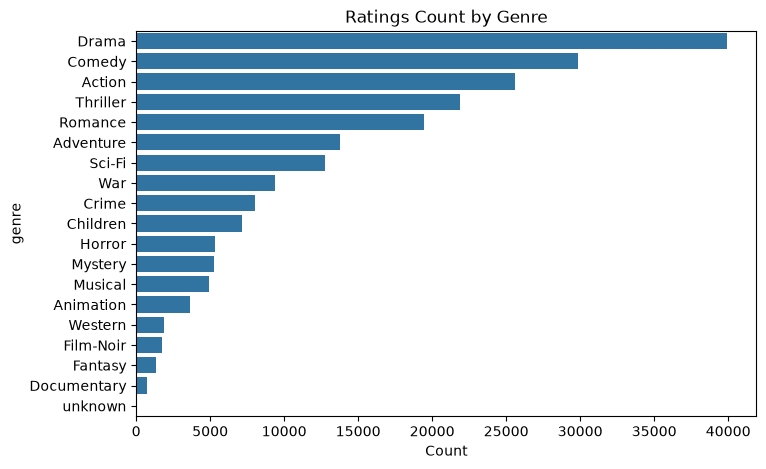

In [4]:
# 1. Explode genres and count ratings
genre_counts = df.assign(genre=df['genres'].str.split('|')).explode('genre')['genre'].value_counts()

# 2. Table
display(genre_counts.to_frame('ratings_count'))

# 3. Chart
plt.figure(figsize=(8, 5))
sns.barplot(x=genre_counts.values, y=genre_counts.index)
plt.title('Ratings Count by Genre')
plt.xlabel('Count')
plt.show()

**✏️ My answer (with numbers):** _(Which genres dominate, by how much, and what exactly did you count?)_

Drama is the genre that dominates, having around 10,000 more ratings than its runner up, at 39,895 ratings versus Comedy's 29,832 ratings. What I counted was how many total ratings each genre of movies had. 

## Q2. Genre satisfaction

**Which genres have the highest average rating? Which have the lowest?**

Show how much data is behind each average (for example, the count next to it). An average of 10 ratings and an average of 10,000 ratings are not the same kind of evidence.

,mean,count
genre,,
Film-Noir,3.92,1733
War,3.82,9398
Drama,3.69,39895
Documentary,3.67,758
Mystery,3.64,5245
Crime,3.63,8055
Romance,3.62,19461
Western,3.61,1854
Animation,3.58,3605


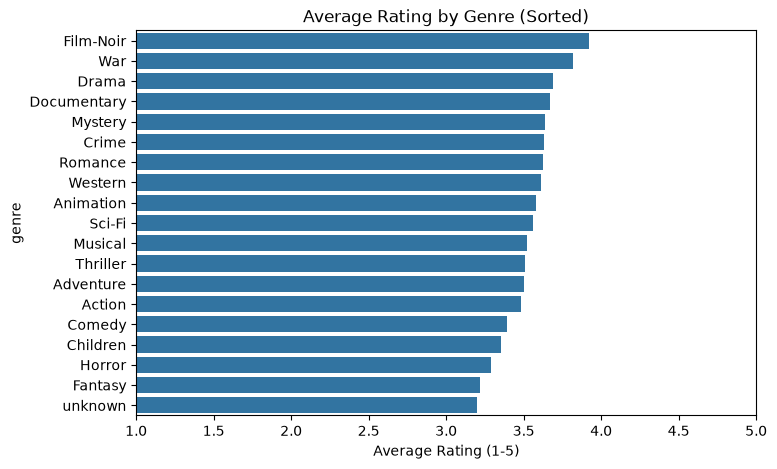

In [5]:
# 1. Explode genres and aggregate mean rating + count
exploded = df.assign(genre=df['genres'].str.split('|')).explode('genre')
genre_stats = exploded.groupby('genre')['rating'].agg(['mean', 'count']).sort_values('mean', ascending=False)

# 2. Table showing all genres with average and sample size
display(genre_stats.round(2))

# 3. Chart: average rating with a visual marker/threshold
plt.figure(figsize=(8, 5))
sns.barplot(x=genre_stats['mean'], y=genre_stats.index)
plt.title('Average Rating by Genre (Sorted)')
plt.xlabel('Average Rating (1-5)')
plt.xlim(1, 5)  # ratings range from 1 to 5
plt.show()

**✏️ My answer (with numbers):** _(Top and bottom genres, their averages, and how much data each one rests on.)_

The highest rated genre was Film-Noir, with an average rating of 3.82. However, it only has 1,733 ratings, which is relatively small in a sample size of 100,000. The lowest rated genre is listed as "unknown". Since that is meaningless in this context, I will go to the next lowest rated genre, which is Fantasy, at 3.22. Since the "unknown" genre has an average of 3.20, there is only a difference of 0.02 anyway, meaning that it doesn't make a huge difference to label the Fantasy genre as having the lowest ratings. Fantasy has even less reviews, sitting at only 1,352. The two runner-ups for both the top and bottom genres have a significantly larger review count, so their average reviews may be more "accurate" due to this. (Especially Drama, which is the 3rd highest rated, and has a whopping 39,895 reviews, which is the most reviews out of any genre!)

## Q3. Ratings over time

**How has the mean rating changed across movie release years?**

Show how many ratings each year is based on, alongside the trend.

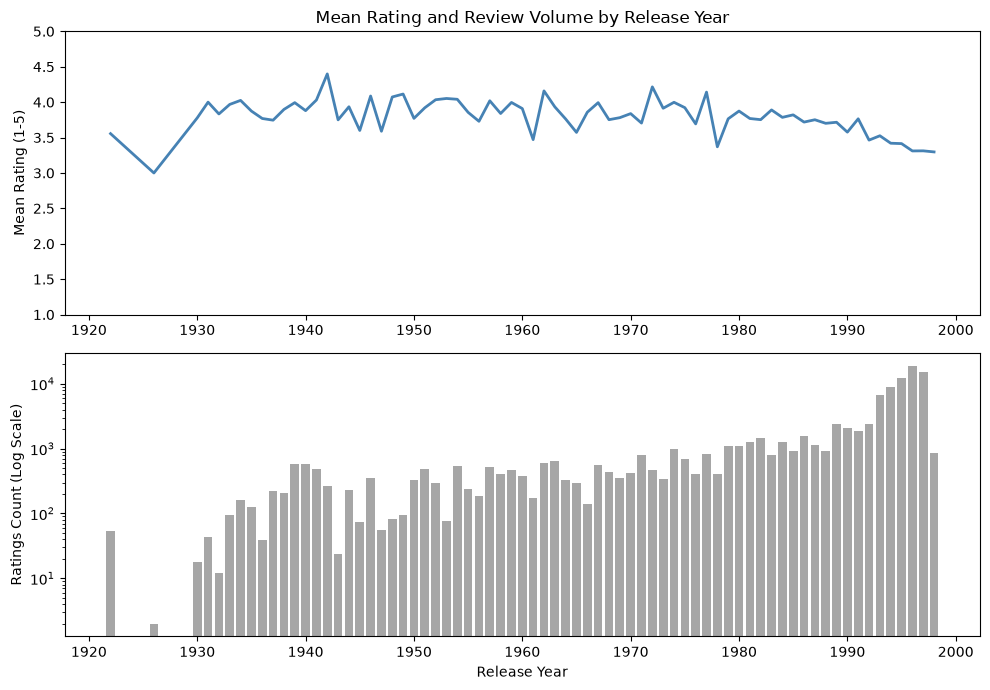

In [10]:
# 1. Group by release year, drop missing years, aggregate mean + count
yearly = df.dropna(subset=['year']).groupby('year')['rating'].agg(['mean', 'count'])

# 2. Plot with explicit year labels visible
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

# Top: Mean rating line
ax1.plot(yearly.index, yearly['mean'], color='steelblue', lw=2)
ax1.set_ylabel('Mean Rating (1-5)')
ax1.set_title('Mean Rating and Review Volume by Release Year')
ax1.set_ylim(1, 5)
# Show year numbers under the line chart as well:
ax1.tick_params(labelbottom=True)

# Bottom: Rating counts with log scale
ax2.bar(yearly.index, yearly['count'], color='gray', alpha=0.7)
ax2.set_yscale('log')
ax2.set_ylabel('Ratings Count (Log Scale)')
ax2.set_xlabel('Release Year')

plt.tight_layout()
plt.show()

In [11]:
# 1. Group by release year, drop missing years, aggregate mean + count
yearly = df.dropna(subset=['year']).groupby('year')['rating'].agg(
    mean_rating='mean',
    ratings_count='count'
).round(2)

# 2. Show the earliest years in the dataset
print("--- Earliest Release Years ---")
display(yearly.head(10))

# 3. Show the peak / most recent years in the dataset
print("\n--- Latest / Peak Release Years ---")
display(yearly.tail(10))

--- Earliest Release Years ---


,mean_rating,ratings_count
year,,
1922.0,3.56,54
1926.0,3.00,2
1930.0,3.78,18
1931.0,4.00,44
1932.0,3.83,12
1933.0,3.97,94
1934.0,4.02,161
1935.0,3.87,127
1936.0,3.77,39



--- Latest / Peak Release Years ---


,mean_rating,ratings_count
year,,
1989.0,3.72,2360
1990.0,3.58,2092
1991.0,3.76,1901
1992.0,3.46,2386
1993.0,3.53,6671
1994.0,3.42,9034
1995.0,3.41,12389
1996.0,3.31,18744
1997.0,3.31,15384


**✏️ My answer (with numbers):** _(What's the trend? Is it equally believable across the whole timeline?)_

There doesn't seem to be a clear, consistent trend across the data, besides the fact that there were multiple dips and spikes in the average ratings for movies. My best guess for this is due to certain historical events such as wars, political unrest, social changes, etc. It could also be due to certain movies coming out that were popular (and got many ratings and reviews), and may have lead to either a surge in positive or negative reviews in the dataset overall due to their sheer popularity. The average ratings also have less of a change as time goes on, because there larger rises and falls in the average over the years from the 1920s to round the 1980s. This may just be due to the majority of the data being from movies in those years, meaning that their average ratings are less sensitive to extreme values. Due to this, it is not equally believeable across the entire timeline, because some earlier years have a ridiculously small sample size, such as 2 reviews in 1926. 

## Q4. Best movies, with a floor

**What are the 5 best-rated movies that have at least 50 ratings? What changes if you raise the floor to 150?**

In [12]:
# 1. Group by movie title, calculate mean rating and count
movie_stats = df.groupby('title')['rating'].agg(
    mean_rating='mean',
    ratings_count='count'
).sort_values(by=['mean_rating', 'ratings_count'], ascending=[False, False])

# 2. Table: Top 5 with at least 50 ratings (>= 50)
top_50 = movie_stats[movie_stats['ratings_count'] >= 50].head(5).round(2)
print("--- Top 5 Movies (Min 50 Ratings) ---")
display(top_50)

# 3. Table: Top 5 with at least 150 ratings (>= 150)
top_150 = movie_stats[movie_stats['ratings_count'] >= 150].head(5).round(2)
print("\n--- Top 5 Movies (Min 150 Ratings) ---")
display(top_150)

--- Top 5 Movies (Min 50 Ratings) ---


,mean_rating,ratings_count
title,,
"Close Shave, A (1995)",4.49,112
Schindler's List (1993),4.47,298
"Wrong Trousers, The (1993)",4.47,118
Casablanca (1942),4.46,243
Wallace & Gromit: The Best of Aardman Animation (1996),4.45,67



--- Top 5 Movies (Min 150 Ratings) ---


,mean_rating,ratings_count
title,,
Schindler's List (1993),4.47,298
Casablanca (1942),4.46,243
"Shawshank Redemption, The (1994)",4.45,283
Rear Window (1954),4.39,209
"Usual Suspects, The (1995)",4.39,267


**✏️ My answer (with numbers):** _(Both top-5 lists. Which movies dropped out or moved in when the floor went up, and what does that say about small samples?)_

The movies that dropped out when the floor went up were A Close Shave (#1, 4.49/5, 112 reviews), The Wrong Trousers (#3, 4.47/5, 118 reviews), and Wallace & Gromit (#5, 4.45/5, 67 reviews). The movies that took its place were The Shawshank Redemption (#3, 4.45/5, 283 reviews), Rear Window (#4, 4.39/5, 209 reviews), and The Usual Suspects (#5, 4.39/5, 267 reviews). The two movies that stayed in both lists actually ranked higher in the list with a minimum of 150 ratings than in the list with a minimum of only 50 ratings. What this says about small samples is that they are not as reliable as larger samples, because there are less chances to collect data points that represent the population. I also noticed that, likely due to this, the average ratings are slightly lower in the larger sample than in the smaller sample. The range is 4.49 to 4.45 in the smaller sample versus 4.47 to 4.39 in the larger sample. This does not necessarily mean that the movies in the smaller sample are "better", but could have just gotten higher reviews due to random chance when sampling. They are only comparable when they both have reasonably large and similar sample sizes. 

> 🔒 **Stop here.** Parts 1 and 2 should be completely filled in before you open your dashboard.

## 3.1 How the dashboard got built

**Prompt 1**

- **What I asked:** I asked the AI to inspect `movie_ratings.csv`, explain the calculations and chart types needed for the four MovieLens questions, and recommend how to handle multiple genres and rating thresholds before writing code.
- **What the AI gave me first:** It explained how to count distinct movies by genre, calculate average ratings by genre and release year, and rank movies using minimum rating counts of 50 and 150. It recommended horizontal bar charts and a line chart.
- **What I changed or accepted without checking:** I accepted its analysis and recommendations without changing them.

**Prompt 2**

- **What I asked:** I asked the AI to build the complete Streamlit dashboard in `app.py`, create `requirements.txt`, include all four visualizations and two interactive sliders, and handle missing years and unknown genres.
- **What the AI gave me first:** It created the dashboard with the required charts, a year-range slider, a minimum-rating slider, and a requirements file.
- **What I changed or accepted without checking:** I initially accepted the generated code without modifying it. I then ran the dashboard and tested the charts and interactive controls, which worked as expected.

## 3.2 Compare the answers

Read the answer off your dashboard for each question and put it next to yours.

**Q1**
- Dashboard says: Count distinct movies in each genre, counting a multi-genre movie once in every genre it belongs to.
- I say: Count ratings per genre, with each rating contributing to every genre assigned to the movie.
- Same? (yes / partly / no): No
- If different, why? The dashboard counts unique movies, while my approach counts individual ratings. A popular movie contributes more to my genre totals, but only one movie to each of the dashboard's genre totals.

**Q2**
- Dashboard says: Calculate the mean of all individual ratings for movies in each genre, including ratings for multi-genre movies in every applicable genre. The unknown genre is excluded.
- I say: Calculate the mean of all ratings assigned to each genre and require at least 500 ratings.
- Same? (yes / partly / no): Partly
- If different, why? Both use rating-weighted averages, but my original approach includes a minimum of 500 ratings per genre. The dashboard description does not mention applying that cutoff.

**Q3**
- Dashboard says: Calculate mean ratings by movie release year and exclude movies with missing release years from this chart.
- I say: Calculate mean ratings by release year, show the number of ratings per year, and try to recover missing years from titles before dropping unresolved rows.
- Same? (yes / partly / no): Partly
- If different, why? Both use movie release year rather than rating submission year. However, my approach attempts to recover missing years and show data volume, while the dashboard excludes missing years and does not display rating counts in the chart description.

**Q4**
- Dashboard says: Rank the top five movies by average rating, using a minimum rating-count threshold and breaking ties by rating count and then title. The threshold can be adjusted.
- I say: Rank movies by average rating, include movies with exactly 50 ratings, and break ties using total rating count.
- Same? (yes / partly / no): Yes, for the 50-rating cutoff.
- If different, why? The dashboard uses the same inclusive minimum of 50 ratings and the same main tie-breaker. It also lets me change the threshold, including comparing 50 versus 150 ratings, and uses title as an additional tie-breaker.

**When numbers differ, check these first.** Most mismatches come from one of these:

- Counting **ratings** vs. counting **movies**
- One row per rating vs. **one row per rating per genre** (after exploding)
- **Mean of all ratings** vs. the mean of each movie's average
- "At least 50" as ≥ vs. >, or applying the floor before vs. after another step
- What happened to movies with a **missing year**
- Genres with **tiny sample sizes** left in or filtered out

**✏️ Pick two questions and explain what's going on** (2 to 3 sentences each). Track down the *actual cause*: read your dashboard's code, or re-run it with one change. "The AI did it differently" is not an explanation. If the answers match, say why you now trust them.

Q1: The dashboard counts distinct movies rather than individual ratings. For example, a movie with 200 ratings contributes only one movie to each of its genres. My original approach would count all 200 ratings, which measures audience engagement rather than the number of movies represented in each genre.

Q2: Both approaches calculate genre averages using individual ratings, so a rating for a multi-genre movie contributes to every applicable genre. However, my original plan also required at least 500 ratings per genre, while the dashboard does not describe that filter. This difference could affect which genres I consider reliable enough to compare.

## 3.3 Chart choices

**Q1**
- Chart the dashboard used: Horizontal bar graph/chart
- Chart I used: Horizontal bar graph/chart
- Which communicates the answer better, and why? N/A, both the same

**Q2**
- Chart the dashboard used: Horizontal bar graph/chart
- Chart I used: Horizontal bar graph/chart
- Which communicates the answer better, and why? N/A, both the same

**Q3**
- Chart the dashboard used: Line chart/line graph
- Chart I used: Line chart/line graph and histogram
- Which communicates the answer better, and why? My approach communicates the answer better. Mine communicates it better. The dashboard's line chart only shows the average score, making it look like 1930 and 1995 have the same amount of proof behind them. My chart adds the bar chart underneath, which immediately shows that the 1990s have tens of thousands of reviews, while early years only have a tiny handful. Showing the review counts prevents the viewer from being misled.

**Q4**
- Chart the dashboard used: ranked (or sorted) horizontal bar chart with data labels
- Chart I used: N/A, did not use a chart, only tables with the movie names, their mean ratings, and the number of ratings for each minimum sample size (50 vs 150). 
- Which communicates the answer better, and why? The tables communicate the answer better.Because the top 5 movies all have nearly identical scores (between roughly 4.45 and 4.49), all five bars on the chart look virtually the same length. The chart forces you to read the text labels anyway just to see the tiny differences. A clean table directly shows the exact numbers side-by-side, making it much easier to compare both the 50 and 150 thresholds and clearly see which titles moved in or out.   

Use what you learned about chart choice and misleading charts (Week 5) and this week's lecture. Is it sorted? Are the labels readable? Are the axes honest? Does it show how much data is behind each number?

## 3.4 What can this data actually tell you?

**Answer at least 3 of these 5**, using your own results as evidence.

**1. Who is in this data?** Check the fewest and the most ratings any single user has given (`df.groupby('user_id').size()`), and look at `rating_year`. What kind of person ends up in a dataset like this, and who is missing? How might that tilt your Q2 answer? *(Week 5: sampling bias)*

**2. How sure are you about the bottom genre?** Take the lowest-rated genre from your Q2. How many ratings *and* how many distinct movies is it built on? Estimate a rough 95% interval: mean ± 1.96 × std / √n. Would you bet it's truly the worst genre? *(Week 5: standard error and confidence intervals. Also ask yourself: are 5,000 ratings of the same handful of movies really 5,000 independent pieces of evidence? Remember the one-row-per-model lesson from last week's homework.)*

**3. What can Q3 really say about time?** How many different values does `rating_year` have? So can this data tell you whether people's taste changed over time? What does your Q3 trend actually describe instead? Why might an old movie in this dataset score higher than a recent one? *(Think: who rates a 1940s film in 1997, and which old movies are even in the data?)*

**4. Does "average" depend on how you average?** Recompute Q2 two ways: (a) average over all ratings, (b) average each movie first, then average the movies within each genre. Does the top genre change? "Which genre do *people* like most?" and "which genre has the best *movies*?" are different questions. *(Week 5: confounding, Simpson's paradox)*

**5. Deployment risk.** A studio exec uses your dashboard to decide which genre to green-light. What's the most misleading conclusion they could draw from one of your charts? Write the one-line caveat you'd put under that chart.

**✏️ Your answers:** _(label each one with its number)_

1. Every user in this dataset has rated at least 20 movies (and some users rated over 700), and all the ratings were collected in just two years: 1997 and 1998. The users also lean young (average age is around 33) and heavily male (~70%+).This means the data represents movie fans in the late 1990s who knew how to use the internet, not the general public. Casual viewers, older demographics, and people without computers in 1997 are basically missing. This skews our Q2 satisfaction results because genres like Film-Noir or Sci-Fi might score higher simply because they appeal directly to this specific group, while genres like Romance or Children's films might get dragged down by viewers who weren't the target audience.

3. The column rating_year only has two values: 1997 and 1998. Because of that, this data cannot tell us if people's tastes changed over time, since all ratings were collected in that tiny window. Instead, the Q3 trend only describes how 1997–1998 viewers felt about movies from different release eras. Older movies (from the 1930s or 1940s) score higher mainly because of  the only people watching and rating a 1942 movie in 1997 are people who sought out a classic like Casablanca. Meanwhile, movies from 1996–1997 include every average or bad movie that just came out in theaters, which naturally pulls their average scores down.

5. The most misleading conclusion an executive could draw is looking at Q2 and deciding to green-light a Film-Noir movie because it has the highest satisfaction score (~3.82). They would completely miss that Film-Noir had fewer than 2,000 total ratings, meaning it has a tiny, niche audience that won't sell enough tickets to turn a profit compared to mainstream genres like Drama or Comedy.

## 3.5 Verdict

**Where I'd override the AI** (something it got wrong, hid, or did poorly, and what your version did better): I would change the genre distribution to count ratings instead of distinct movies because I wanted to measure audience engagement with each genre, not just how many movies belong to it.

**Where the AI held up** (something it did well, or a choice you doubted at first that turned out right): The AI correctly distinguished between movie release year and rating submission year. Using release year is important because the question asks how ratings vary by the year movies came out.

**One sentence:** looking back at both weeks, who was driving, you or the AI, and when?: I was driving when deciding what questions to answer and what the results should mean, while the AI helped implement the calculations and charts, although I still needed to check whether its choices matched my original decisions.

---
## Optional stretch

Only if you want more practice:

- Pick 4 genres. How does the mean rating change as viewer age increases? (Try more than 4 and see which genres make the most interesting chart.)
- Plot number of ratings vs. mean rating for each movie. Do the most-rated movies get higher ratings? Is there a correlation? *(Week 5: correlation vs. causation)*

---
## Before you submit

- [ ] Copy this notebook into the `exercise/` folder and rename it `Firstname_Lastname_week_06_exercise.ipynb`
- [ ] **Kernel → Restart & Run All** and make sure it runs top to bottom with your charts showing
- [ ] Every ✏️ cell and every fill-in line is filled in
- [ ] Open a PR from your fork, same as every other week